## Importaciones

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Información 2025

In [2]:
ruta_empresas = "../data/2025/Empresas_CCAA_2025.csv"
ruta_padron = "../data/2025/padron_67988.csv"
ruta_salud = "../data/2025/ESdEadulto_2025.tab"

#Carga y limpieza
df_empresas_2025 = pd.read_csv(ruta_empresas, sep=";", encoding="latin1", thousands=".")
df_padron_2025 = pd.read_csv(ruta_padron, sep=";", encoding="latin1", thousands=".")
df_salud_2025 = pd.read_csv(ruta_salud, sep="\t")

df_padron_2025 = df_padron_2025[df_padron_2025['Provincias'].isna()].dropna(subset=['Comunidades y Ciudades Autónomas']) 
df_padron_2025['CCAA_cod'] = df_padron_2025['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_padron_2025['CCAA_Nombre'] = df_padron_2025['Comunidades y Ciudades Autónomas'].str[3:].str.strip()
df_padron_ccaa_2025 = df_padron_2025[['CCAA_cod', 'CCAA_Nombre', 'Total']].rename(columns={'Total': 'Poblacion'})

df_empresas_2025 = df_empresas_2025[df_empresas_2025['Comunidades y Ciudades Autónomas'] != 'Total Nacional']
df_empresas_2025['CCAA_cod'] = df_empresas_2025['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_ocio_2025 = df_empresas_2025.groupby('CCAA_cod')['Total'].sum().reset_index().rename(columns={'Total': 'Total_Locales'})

df_salud_valido_2025 = df_salud_2025[df_salud_2025['C5b_22'].isin([1, 2])]
estres_ccaa_2025 = (df_salud_valido_2025[df_salud_valido_2025['C5b_22'] == 1].groupby('CCAA').size() / 
               df_salud_valido_2025.groupby('CCAA').size() * 100).reset_index()
estres_ccaa_2025.columns = ['CCAA_cod', 'Pct_Ansiedad']

#Merge y Métrica (Manteniendo números crudos)
df_final_2025 = pd.merge(df_ocio_2025, df_padron_ccaa_2025, on='CCAA_cod')
df_final_2025 = pd.merge(df_final_2025, estres_ccaa_2025, on='CCAA_cod')
df_final_2025['Locales_por_100k_2025'] = (df_final_2025['Total_Locales'] / df_final_2025['Poblacion']) * 100000
df_final_2025 = df_final_2025.set_index('CCAA_Nombre').drop(columns=['CCAA_cod'])

#FORMATO DE MILES Y DECIMALES PARA LECTURA
def formato_esp(x, decimales=0):
    if decimales == 0:
        return f"{x:,.0f}".replace(",", ".")
    else:
        # Reemplazamos la coma original por 'X', el punto por coma, y la 'X' por punto
        return f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

df_visual = df_final_2025.copy()
df_visual['Total_Locales'] = df_visual['Total_Locales'].apply(lambda x: formato_esp(x, 0))
df_visual['Poblacion'] = df_visual['Poblacion'].apply(lambda x: formato_esp(x, 0))
df_visual['Pct_Ansiedad'] = df_visual['Pct_Ansiedad'].apply(lambda x: formato_esp(x, 2) + " %")
df_visual['Locales_por_100k_2025'] = df_visual['Locales_por_100k_2025'].apply(lambda x: formato_esp(x, 2))

#print(df_final_2025)
display(df_visual)

,Total_Locales,Poblacion,Pct_Ansiedad,Locales_por_100k_2025
CCAA_Nombre,,,,
Andalucía,66.687,8.676.713,"87,65 %","768,57"
Aragón,10.144,1.364.621,"82,14 %","743,36"
"Asturias, Principado de",9.734,1.015.128,"83,76 %","958,89"
"Balears, Illes",14.368,1.249.844,"85,06 %","1.149,58"
Canarias,21.694,2.258.866,"80,41 %","960,39"
Cantabria,5.571,593.623,"84,15 %","938,47"
Castilla y León,20.143,2.401.221,"89,04 %","838,86"
Castilla - La Mancha,13.928,2.126.378,"87,50 %","655,01"
Cataluña,64.034,8.124.126,"80,66 %","788,20"


# Gáfico de dispersión y de ansiedad

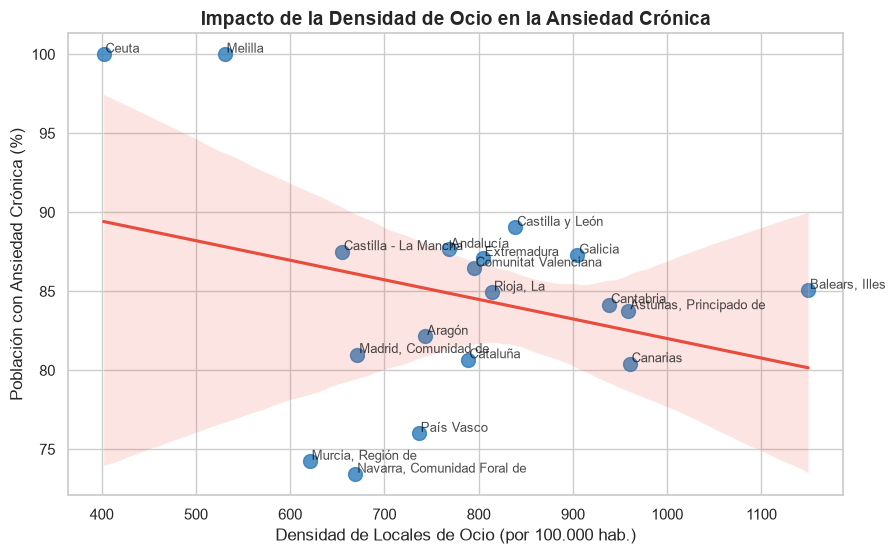

C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_15272\3189586660.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ordenado, x=df_ordenado.index, y='Pct_Ansiedad', palette='Reds_r')


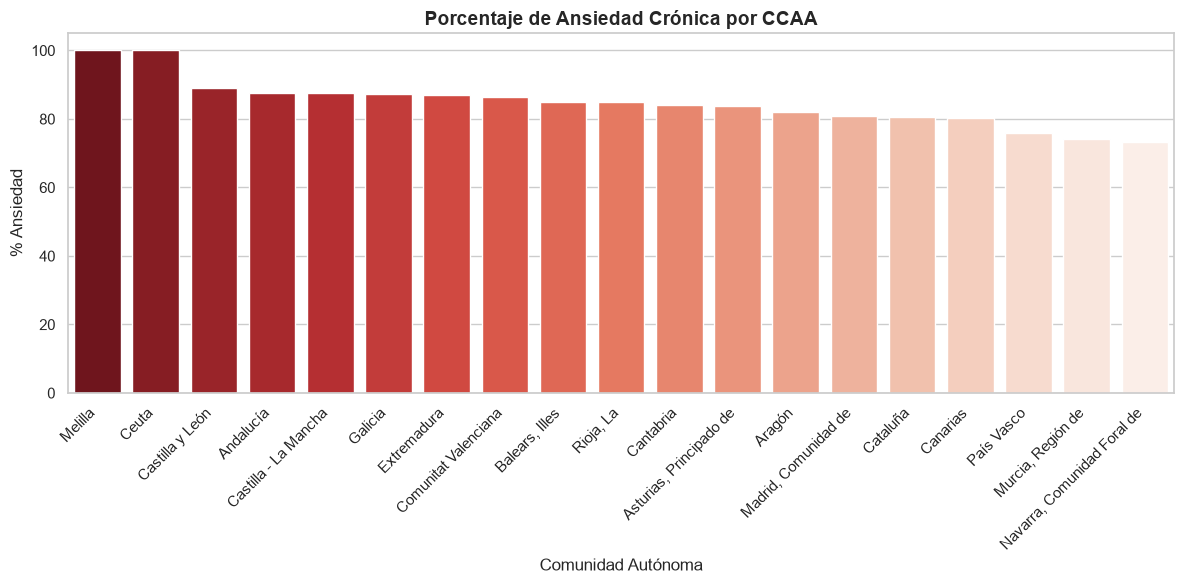

In [3]:
sns.set_theme(style="whitegrid")

# Gráfico de dispersión
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_final_2025, 
    x='Locales_por_100k_2025', 
    y='Pct_Ansiedad', 
    scatter_kws={'s': 100, 'color': '#2b7bba'},
    line_kws={'color': '#e74c3c'}
)

for idx, row in df_final_2025.iterrows():
    plt.text(row['Locales_por_100k_2025'] + 2, row['Pct_Ansiedad'] + 0.1, idx, 
             fontsize=9, color='black', alpha=0.7)

plt.title('Impacto de la Densidad de Ocio en la Ansiedad Crónica', fontsize=14, fontweight='bold')
plt.xlabel('Densidad de Locales de Ocio (por 100.000 hab.)', fontsize=12)
plt.ylabel('Población con Ansiedad Crónica (%)', fontsize=12)
plt.show()

# Gráfico de barras
plt.figure(figsize=(12, 6))
df_ordenado = df_final_2025.sort_values('Pct_Ansiedad', ascending=False)
sns.barplot(data=df_ordenado, x=df_ordenado.index, y='Pct_Ansiedad', palette='Reds_r')
plt.title('Porcentaje de Ansiedad Crónica por CCAA', fontsize=14, fontweight='bold')
plt.xlabel('Comunidad Autónoma', fontsize=12)
plt.ylabel('% Ansiedad', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_15272\2821865233.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=df2_locales_2025, x='Total_Locales', y=df2_locales_2025.index, palette='Blues_r')
C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_15272\2821865233.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df2_ansiedad_2025, x='Pct_Ansiedad', y=df2_ansiedad_2025.index, palette='Reds_r')


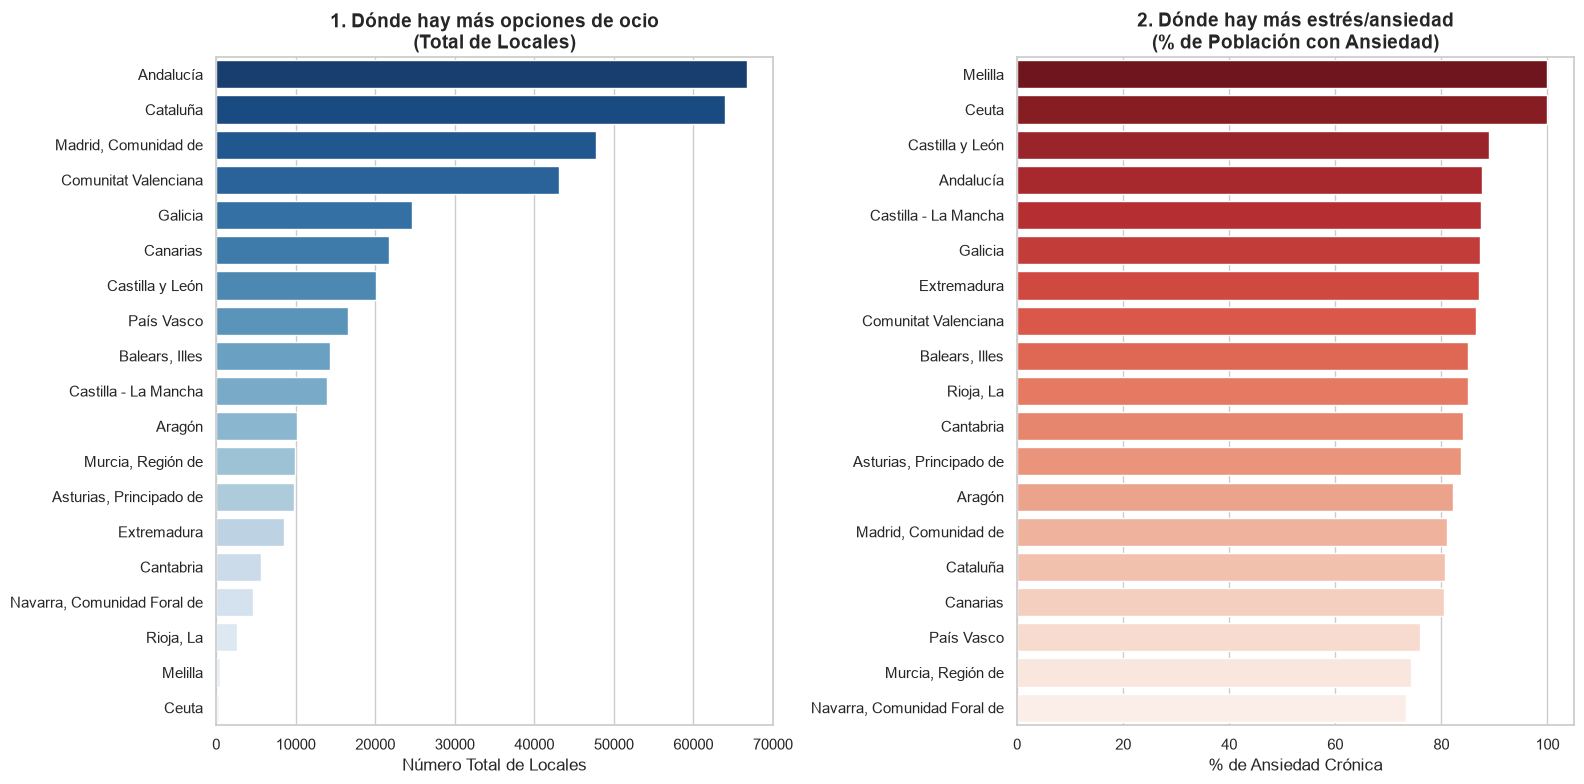

In [4]:
ruta2_empresas_2025 = "../data/2025/Empresas_CCAA_2025.csv"
ruta2_salud_2025 = "../data/2025/ESdEadulto_2025.tab"

df2_empresas_2025 = pd.read_csv(ruta2_empresas_2025, sep=";", encoding="latin1", thousands=".")
df2_salud_2025 = pd.read_csv(ruta2_salud_2025, sep="\t")

#Limpieza de Empresas (Ocio) - Cifras Brutas
df2_empresas_2025 = df2_empresas_2025[df2_empresas_2025['Comunidades y Ciudades Autónomas'] != 'Total Nacional']
df2_empresas_2025['CCAA_cod'] = df2_empresas_2025['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df2_empresas_2025['CCAA_Nombre'] = df2_empresas_2025['Comunidades y Ciudades Autónomas'].str[3:].str.strip()

df2_ocio_2025 = df2_empresas_2025.groupby(['CCAA_cod', 'CCAA_Nombre'])['Total'].sum().reset_index()
df2_ocio_2025 = df2_ocio_2025.rename(columns={'Total': 'Total_Locales'})

#Limpieza de Salud (Ansiedad Crónica)
df2_salud_valido_2025 = df2_salud_2025[df2_salud_2025['C5b_22'].isin([1, 2])]
estres2_ccaa_2025 = (df2_salud_valido_2025[df2_salud_valido_2025['C5b_22'] == 1].groupby('CCAA').size() / 
               df2_salud_valido_2025.groupby('CCAA').size() * 100).reset_index()
estres2_ccaa_2025.columns = ['CCAA_cod', 'Pct_Ansiedad']

#Unir tablas
df2_final_2025 = pd.merge(df2_ocio_2025, estres2_ccaa_2025, on='CCAA_cod')
df2_final_2025 = df2_final_2025.set_index('CCAA_Nombre')

#VISUALIZACIÓN
sns.set_theme(style="whitegrid")

#Creamos una figura con 2 subgráficos (uno al lado del otro)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

#Gráfico Izquierdo: Ranking de Locales Totales (Cifras Brutas)
df2_locales_2025 = df2_final_2025.sort_values('Total_Locales', ascending=False)
sns.barplot(ax=axes[0], data=df2_locales_2025, x='Total_Locales', y=df2_locales_2025.index, palette='Blues_r')
axes[0].set_title('1. Dónde hay más opciones de ocio\n(Total de Locales)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Número Total de Locales', fontsize=12)
axes[0].set_ylabel('')

#Gráfico Derecho: Ranking de Ansiedad
df2_ansiedad_2025 = df2_final_2025.sort_values('Pct_Ansiedad', ascending=False)
sns.barplot(ax=axes[1], data=df2_ansiedad_2025, x='Pct_Ansiedad', y=df2_ansiedad_2025.index, palette='Reds_r')
axes[1].set_title('2. Dónde hay más estrés/ansiedad\n(% de Población con Ansiedad)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('% de Ansiedad Crónica', fontsize=12)
axes[1].set_ylabel('')

#Ajustamos el diseño para que no se pisen los textos
plt.tight_layout()
plt.show()

# Gráfico ocio vs ansiedad

C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_15272\1935851536.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(df2_final_2025.index, rotation=45, ha='right')


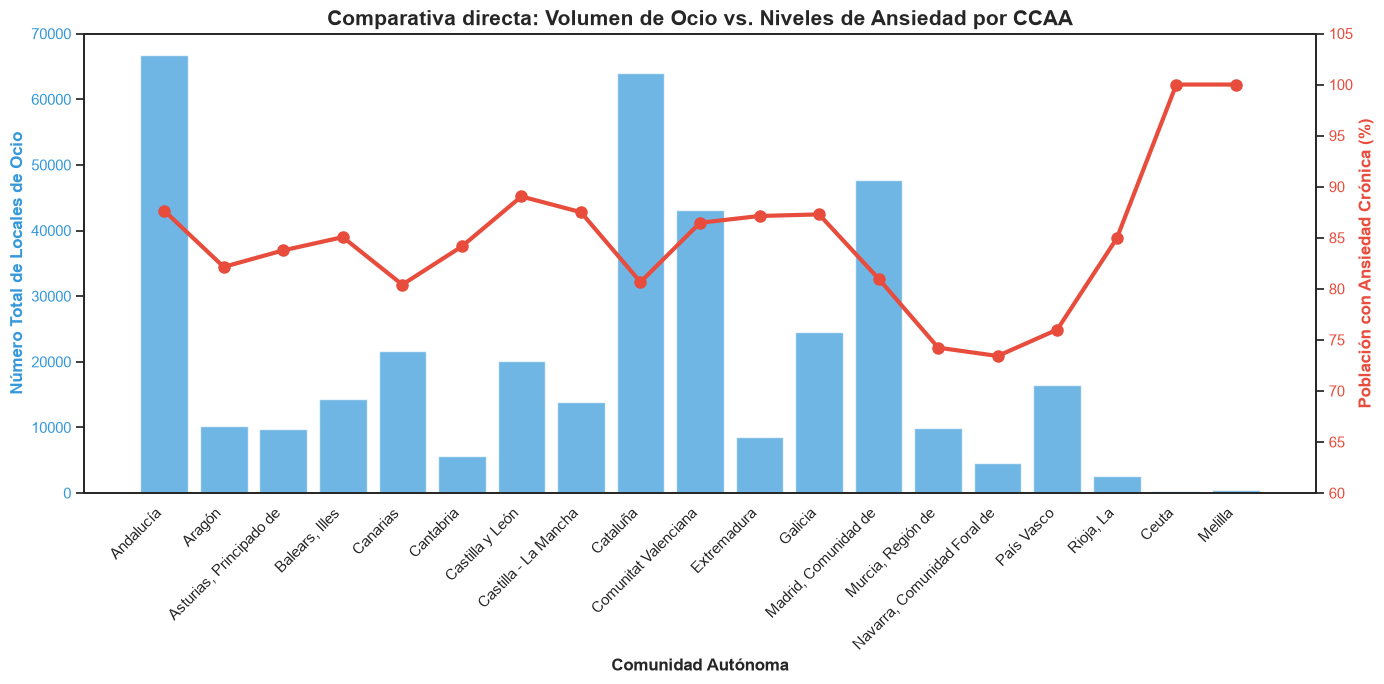

In [5]:
#VISUALIZACIÓN: GRÁFICO COMBINADO (BARRAS + LÍNEA)
sns.set_theme(style="white")
fig, ax1 = plt.subplots(figsize=(14, 7))

# EJE PRINCIPAL (Izquierdo): Barras para los Locales
color_barras = '#3498db'
ax1.bar(df2_final_2025.index, df2_final_2025['Total_Locales'], color=color_barras, alpha=0.7, label='Opciones de Ocio')
ax1.set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')
ax1.set_ylabel('Número Total de Locales de Ocio', color=color_barras, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_barras)
ax1.set_xticklabels(df2_final_2025.index, rotation=45, ha='right')

# EJE SECUNDARIO (Derecho): Línea para la Ansiedad
ax2 = ax1.twinx()  # Crea un segundo eje Y que comparte el mismo eje X
color_linea = '#e74c3c'
ax2.plot(df2_final_2025.index, df2_final_2025['Pct_Ansiedad'], color=color_linea, marker='o', 
         linewidth=3, markersize=8, label='% Ansiedad')
ax2.set_ylabel('Población con Ansiedad Crónica (%)', color=color_linea, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_linea)
# Ajustamos el límite Y para que la línea no se pegue al techo
ax2.set_ylim(bottom=60, top=105) 

# Título y ajustes finales
plt.title('Comparativa directa: Volumen de Ocio vs. Niveles de Ansiedad por CCAA', fontsize=15, fontweight='bold')
fig.tight_layout() # Evita que se corten los nombres de abajo
plt.show()

## Información 2014

In [17]:
ruta_empresas_2014 = "../data/2014/empresas_ccaa_298.csv"
ruta_padron_2014 = "../data/2014/padron_04001.csv"
ruta_salud_2014 = "../data/2014/EESEadulto_2014.csv"

#Carga de los datos
df_empresas_14 = pd.read_csv(ruta_empresas_2014, sep=";", encoding="utf-8-sig", thousands=".", low_memory=False)
df_padron_14 = pd.read_csv(ruta_padron_2014, sep=";", encoding="latin1", thousands=".")
df_salud_14 = pd.read_csv(ruta_salud_2014, sep="\t", low_memory=False)

#Limpieza del Padrón 2014 
df_padron_14 = df_padron_14[df_padron_14['Provincias'].isna()].dropna(subset=['Comunidades y Ciudades Autónomas'])
df_padron_14['CCAA_cod'] = df_padron_14['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_padron_14['CCAA_Nombre'] = df_padron_14['Comunidades y Ciudades Autónomas'].str[3:].str.strip()
df_padron_14_ccaa = df_padron_14.groupby(['CCAA_cod', 'CCAA_Nombre'])['Total'].sum().reset_index()
df_padron_14_ccaa = df_padron_14_ccaa.rename(columns={'Total': 'Poblacion'})

#Limpieza de Empresas (Ocio) 2014
sectores_ocio = [
    '55 Servicios de alojamiento', '56 Servicios de comidas y bebidas', 
    '90 Actividades de creación, artísticas y espectáculos', 
    '91 Actividades de bibliotecas, archivos, museos y otras actividades culturales', 
    '92 Actividades de juegos de azar y apuestas',
    '93 Actividades deportivas, recreativas y de entretenimiento'
]
df_empresas_14 = df_empresas_14[
    (df_empresas_14['Periodo'] == 2014) & 
    (df_empresas_14['Estrato de asalariados'] == 'Total') & 
    (df_empresas_14['Actividad principal'].isin(sectores_ocio)) & 
    (df_empresas_14['Comunidades y Ciudades Autónomas'] != 'Total Nacional')
]
df_empresas_14['CCAA_cod'] = df_empresas_14['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_ocio_14 = df_empresas_14.groupby('CCAA_cod')['Total'].sum().reset_index().rename(columns={'Total': 'Total_Locales'})

#Limpieza de Salud 2014 (¡CORRECCIÓN APLICADA AQUÍ!)
#Forzamos la columna a convertirse en números antes de filtrar
df_salud_14['G25b_21'] = pd.to_numeric(df_salud_14['G25b_21'], errors='coerce')

df_salud_14_valido = df_salud_14[df_salud_14['G25b_21'].isin([1, 2])]
estres_14 = (df_salud_14_valido[df_salud_14_valido['G25b_21'] == 1].groupby('CCAA').size() / 
             df_salud_14_valido.groupby('CCAA').size() * 100).reset_index()
estres_14.columns = ['CCAA_cod', 'Pct_Ansiedad']

#Unir tablas para 2014
df_2014 = pd.merge(df_ocio_14, df_padron_14_ccaa, on='CCAA_cod')
df_2014 = pd.merge(df_2014, estres_14, on='CCAA_cod')
df_2014 = df_2014.drop(columns=['CCAA_cod'])

#Métrica y Ajuste final
df_2014['Locales_por_100k_2014'] = (df_2014['Total_Locales'] / df_2014['Poblacion']) * 100000
df_2014 = df_2014.set_index('CCAA_Nombre')

def formato_esp(x, decimales=0):
    if decimales == 0:
        return f"{x:,.0f}".replace(",", ".")
    else:
        # Reemplazamos la coma original por 'X', el punto por coma, y la 'X' por punto
        return f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
        
df_visual2 = df_2014.copy()
df_visual2['Total_Locales'] = df_visual2['Total_Locales'].apply(lambda x: formato_esp(x, 0))
df_visual2['Poblacion'] = df_visual2['Poblacion'].apply(lambda x: formato_esp(x, 0))
df_visual2['Pct_Ansiedad'] = df_visual2['Pct_Ansiedad'].apply(lambda x: formato_esp(x, 2) + " %")
df_visual2['Locales_por_100k_2014'] = df_visual2['Locales_por_100k_2014'].apply(lambda x: formato_esp(x, 2))
print("Resultados de 2014 listos:")
#print(df_2014)
display(df_visual2)

Resultados de 2014 listos:


,Total_Locales,Poblacion,Pct_Ansiedad,Locales_por_100k_2014
CCAA_Nombre,,,,
Andalucía,57.503,6.941.456,"86,77 %","828,40"
Aragón,10.047,1.128.405,"92,31 %","890,37"
"Asturias, Principado de",9.964,938.233,"91,49 %","1.062,00"
"Balears, Illes",12.149,920.889,"89,41 %","1.319,27"
Canarias,18.870,1.780.640,"91,39 %","1.059,73"
Cantabria,5.158,504.100,"90,70 %","1.023,21"
Castilla y León,22.334,2.173.335,"91,26 %","1.027,64"
Castilla - La Mancha,13.763,1.736.118,"93,85 %","792,75"
Cataluña,57.423,6.265.118,"89,57 %","916,55"


## Evolución Temporal: Comparativa 2014 vs 2025

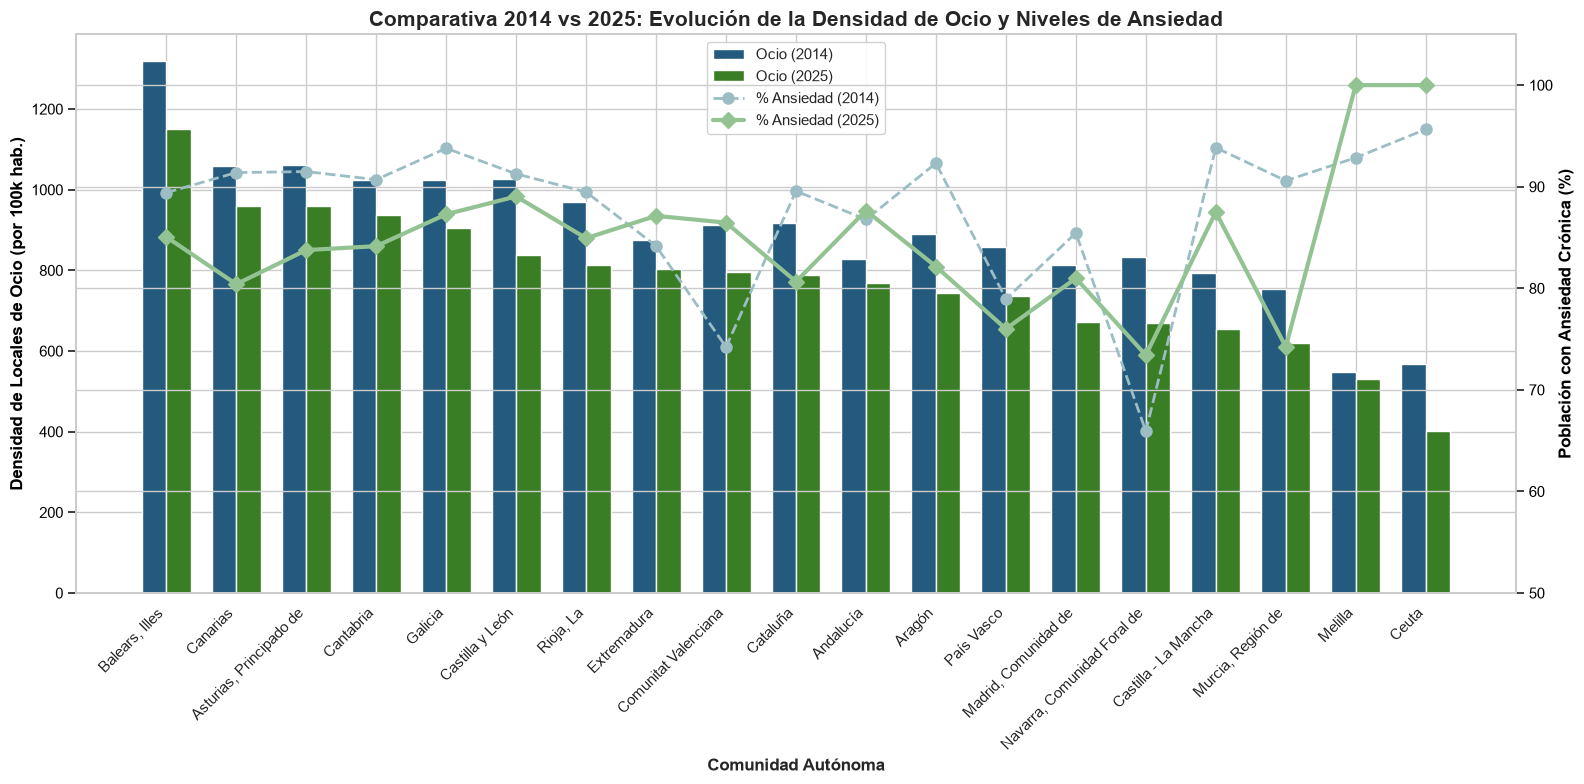

In [7]:
df_comparativo = pd.merge(df_2014, df_final_2025, left_index=True, right_index=True, suffixes=('_2014', '_2025'))
df_comparativo = df_comparativo.sort_values('Locales_por_100k_2025', ascending=False)

#Configuración del gráfico
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(16, 8))

#Posiciones en el eje X para las CCAA
x = np.arange(len(df_comparativo.index))
ancho_barra = 0.35 # Grosor de las barras para que quepan dos por cada CCAA

# EJE PRINCIPAL (IZQUIERDO): BARRAS PARA LOCALES DE OCIO
#Barra 2014 (desplazada a la izquierda)
barra1 = ax1.bar(x - ancho_barra/2, df_comparativo['Locales_por_100k_2014'], 
                 ancho_barra, label='Ocio (2014)', color="#235a7e")
#Barra 2025 (desplazada a la derecha)
barra2 = ax1.bar(x + ancho_barra/2, df_comparativo['Locales_por_100k_2025'], 
                 ancho_barra, label='Ocio (2025)', color="#397e24")

ax1.set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')
ax1.set_ylabel('Densidad de Locales de Ocio (por 100k hab.)', color='#000000', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor="#000000")

#Ponemos los nombres de las CCAA en el centro de los dos grupos de barras
ax1.set_xticks(x)
ax1.set_xticklabels(df_comparativo.index, rotation=45, ha='right')

#EJE SECUNDARIO (DERECHO): LÍNEAS PARA ANSIEDAD
ax2 = ax1.twinx()

#Línea 2014
linea1 = ax2.plot(x, df_comparativo['Pct_Ansiedad_2014'], color="#9bbdc3", 
                  marker='o', linestyle='--', linewidth=2, markersize=8, label='% Ansiedad (2014)')
#Línea 2025
linea2 = ax2.plot(x, df_comparativo['Pct_Ansiedad_2025'], color="#94c393", 
                  marker='D', linestyle='-', linewidth=3, markersize=8, label='% Ansiedad (2025)')

ax2.set_ylabel('Población con Ansiedad Crónica (%)', color='#000000', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#000000')
ax2.set_ylim(bottom=50, top=105) # Ajustamos la escala para que se vean bien las fluctuaciones

# Juntamos las leyendas de los dos ejes
bars_labels = [b.get_label() for b in [barra1, barra2]]
lines_labels = [l.get_label() for l in linea1 + linea2]
ax1.legend([barra1, barra2] + linea1 + linea2, bars_labels + lines_labels, loc='upper center', framealpha=0.9)

plt.title('Comparativa 2014 vs 2025: Evolución de la Densidad de Ocio y Niveles de Ansiedad', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()

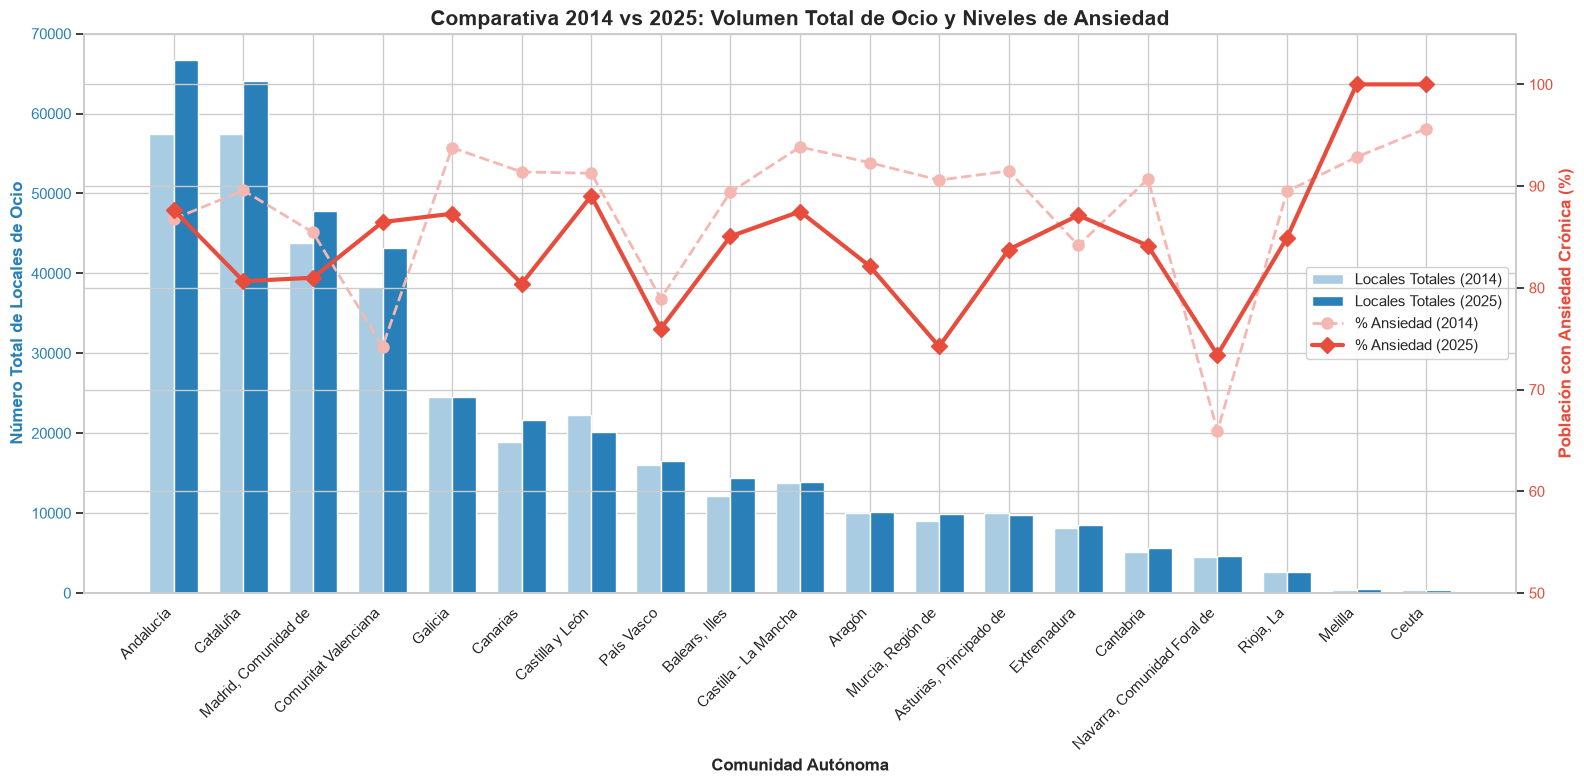

In [8]:
#LIMPIEZA DE DATOS: Asegurarnos de que todo es numérico antes de graficar
def limpiar_numero(x):
    if isinstance(x, str):
        # Quitamos puntos de miles, porcentajes y cambiamos comas por puntos decimales
        texto_limpio = x.replace('.', '').replace('%', '').replace(',', '.').strip()
        return float(texto_limpio)
    return float(x)

df_comparativo['Total_Locales_2014'] = df_comparativo['Total_Locales_2014'].apply(limpiar_numero)
df_comparativo['Total_Locales_2025'] = df_comparativo['Total_Locales_2025'].apply(limpiar_numero)
df_comparativo['Pct_Ansiedad_2014'] = df_comparativo['Pct_Ansiedad_2014'].apply(limpiar_numero)
df_comparativo['Pct_Ansiedad_2025'] = df_comparativo['Pct_Ansiedad_2025'].apply(limpiar_numero)

#Ordenamos por el volumen total de locales en 2025 para que el gráfico quede escalonado
df_comparativo = df_comparativo.sort_values('Total_Locales_2025', ascending=False)

sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(16, 8))

#Posiciones en el eje X para las CCAA
x = np.arange(len(df_comparativo.index))
ancho_barra = 0.35 

#EJE PRINCIPAL (IZQUIERDO): BARRAS PARA LOCALES TOTALES 
barra1 = ax1.bar(x - ancho_barra/2, df_comparativo['Total_Locales_2014'], 
                 ancho_barra, label='Locales Totales (2014)', color='#a9cce3')
barra2 = ax1.bar(x + ancho_barra/2, df_comparativo['Total_Locales_2025'], 
                 ancho_barra, label='Locales Totales (2025)', color='#2980b9')

ax1.set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')
ax1.set_ylabel('Número Total de Locales de Ocio', color='#2980b9', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2980b9')
ax1.set_xticks(x)
ax1.set_xticklabels(df_comparativo.index, rotation=45, ha='right')

#EJE SECUNDARIO (DERECHO): LÍNEAS PARA ANSIEDAD
ax2 = ax1.twinx()

linea1 = ax2.plot(x, df_comparativo['Pct_Ansiedad_2014'], color='#f5b7b1', 
                  marker='o', linestyle='--', linewidth=2, markersize=8, label='% Ansiedad (2014)')
linea2 = ax2.plot(x, df_comparativo['Pct_Ansiedad_2025'], color='#e74c3c', 
                  marker='D', linestyle='-', linewidth=3, markersize=8, label='% Ansiedad (2025)')

ax2.set_ylabel('Población con Ansiedad Crónica (%)', color='#e74c3c', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#e74c3c')
ax2.set_ylim(bottom=50, top=105) 

bars_labels = [b.get_label() for b in [barra1, barra2]]
lines_labels = [l.get_label() for l in linea1 + linea2]
ax1.legend([barra1, barra2] + linea1 + linea2, bars_labels + lines_labels, loc='center right', framealpha=0.9)

plt.title('Comparativa 2014 vs 2025: Volumen Total de Ocio y Niveles de Ansiedad', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()

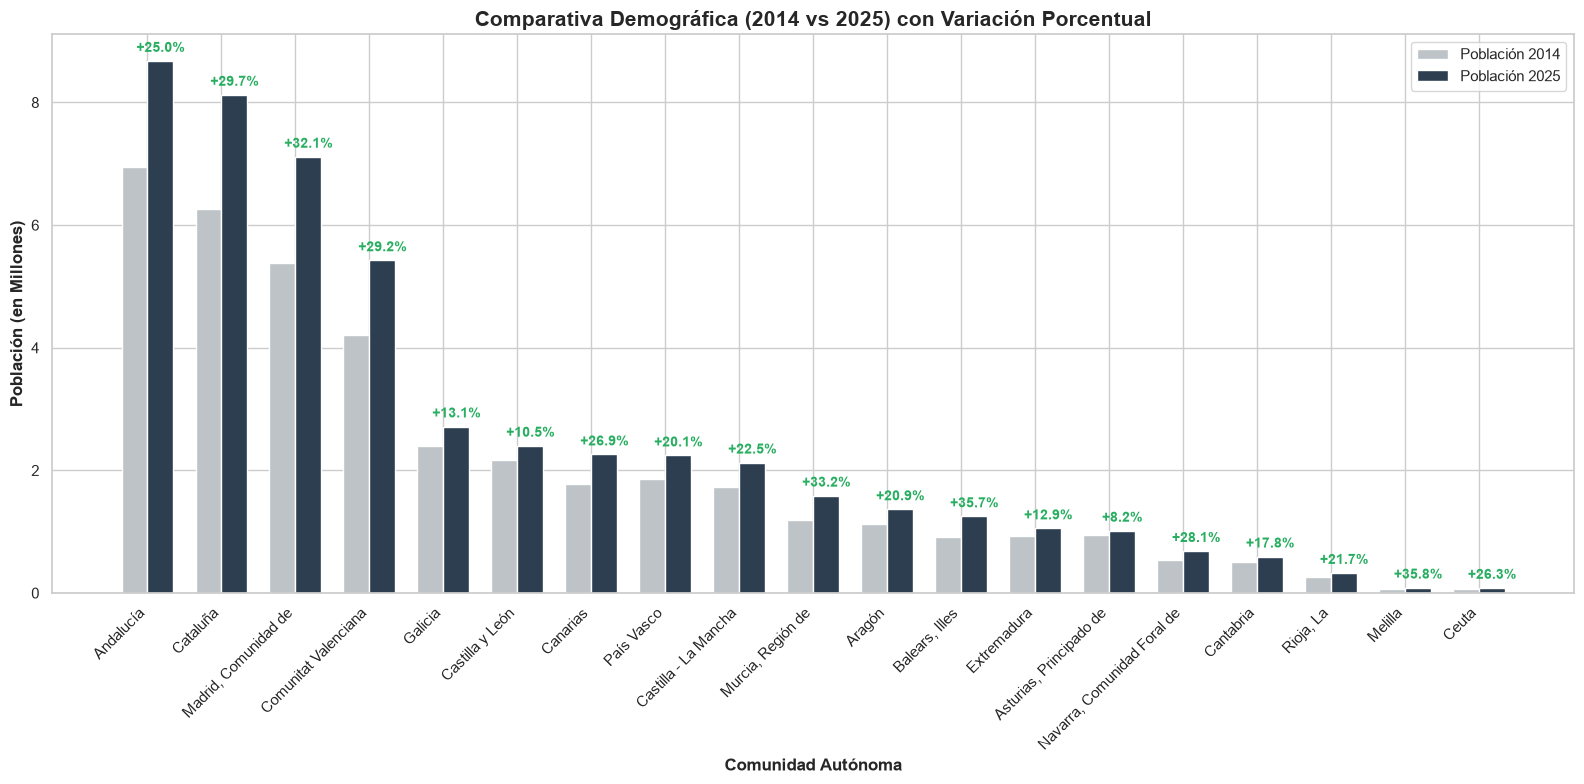

In [9]:
def limpiar_numero(x):
    if isinstance(x, str):
        texto_limpio = x.replace('.', '').replace('%', '').replace(',', '.').strip()
        return float(texto_limpio)
    return float(x)

df_comparativo['Poblacion_2014'] = df_comparativo['Poblacion_2014'].apply(limpiar_numero)
df_comparativo['Poblacion_2025'] = df_comparativo['Poblacion_2025'].apply(limpiar_numero)

#Ordenar de mayor a menor población actual (2025)
df_pob = df_comparativo.sort_values('Poblacion_2025', ascending=False)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 8))

x = np.arange(len(df_pob.index))
ancho_barra = 0.35 

#Dividimos entre un millón para que el eje Y sea muy fácil de leer ("Millones de habitantes")
pob_2014_millones = df_pob['Poblacion_2014'] / 1000000
pob_2025_millones = df_pob['Poblacion_2025'] / 1000000

#Creamos las barras
barra1 = ax.bar(x - ancho_barra/2, pob_2014_millones, ancho_barra, label='Población 2014', color='#bdc3c7')
barra2 = ax.bar(x + ancho_barra/2, pob_2025_millones, ancho_barra, label='Población 2025', color='#2c3e50')

ax.set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')
ax.set_ylabel('Población (en Millones)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_pob.index, rotation=45, ha='right')

#Añadir las etiquetas de variación porcentual (+X% / -X%) encima de las barras
for i in range(len(x)):
    val_2014 = df_pob['Poblacion_2014'].iloc[i]
    val_2025 = df_pob['Poblacion_2025'].iloc[i]
    variacion_pct = ((val_2025 - val_2014) / val_2014) * 100
    
    # Lógica de colores: Verde si crece, Rojo si baja
    color_texto = '#27ae60' if variacion_pct > 0 else '#c0392b'
    signo = '+' if variacion_pct > 0 else ''
    
    ax.text(x[i] + ancho_barra/2, pob_2025_millones.iloc[i] + 0.1, 
            f'{signo}{variacion_pct:.1f}%', 
            ha='center', va='bottom', color=color_texto, fontweight='bold', fontsize=10)

ax.legend()
plt.title('Comparativa Demográfica (2014 vs 2025) con Variación Porcentual', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()

findfont: Failed to find font weight heavy for Arial, now using 900.


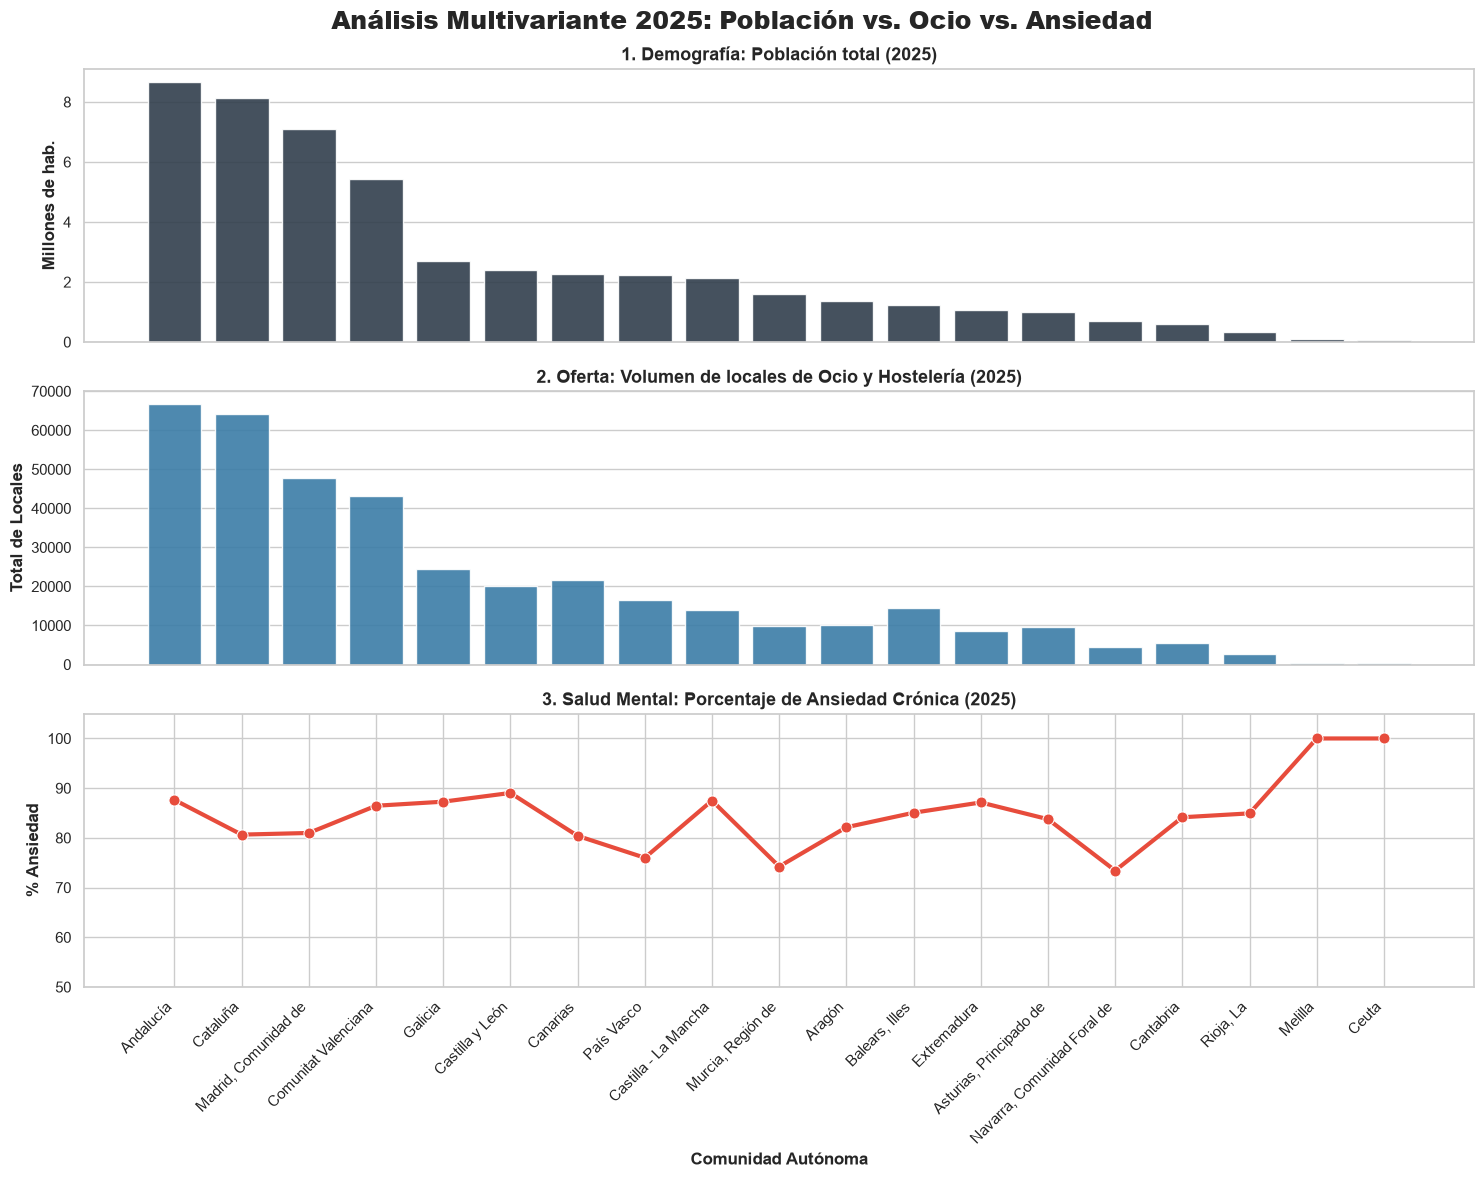

In [10]:
def limpiar_numero(x):
    if isinstance(x, str):
        texto_limpio = x.replace('.', '').replace('%', '').replace(',', '.').strip()
        return float(texto_limpio)
    return float(x)

df_comparativo['Pob_2025_num'] = df_comparativo['Poblacion_2025'].apply(limpiar_numero) / 1000000 # En millones
df_comparativo['Locales_2025_num'] = df_comparativo['Total_Locales_2025'].apply(limpiar_numero)
df_comparativo['Ansiedad_2025_num'] = df_comparativo['Pct_Ansiedad_2025'].apply(limpiar_numero)

#Ordenamos por población de mayor a menor para darle lógica a la lectura
df_triple = df_comparativo.sort_values('Pob_2025_num', ascending=False)

#CONFIGURACIÓN DEL GRÁFICO TRIPLE
sns.set_theme(style="whitegrid")
# Creamos 3 subgráficos (3 filas, 1 columna) que comparten el eje X
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

#PANEL 1: POBLACIÓN
sns.barplot(ax=axes[0], x=df_triple.index, y=df_triple['Pob_2025_num'], color='#2c3e50', alpha=0.9)
axes[0].set_title('1. Demografía: Población total (2025)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Millones de hab.', fontweight='bold')
axes[0].set_xlabel('') # Ocultamos el título del eje X aquí para no repetirlo

#PANEL 2: LOCALES DE OCIO
sns.barplot(ax=axes[1], x=df_triple.index, y=df_triple['Locales_2025_num'], color='#2980b9', alpha=0.9)
axes[1].set_title('2. Oferta: Volumen de locales de Ocio y Hostelería (2025)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Total de Locales', fontweight='bold')
axes[1].set_xlabel('')

#PANEL 3: ANSIEDAD 
sns.lineplot(ax=axes[2], x=df_triple.index, y=df_triple['Ansiedad_2025_num'], 
             color='#e74c3c', marker='o', linewidth=3, markersize=8)
axes[2].set_title('3. Salud Mental: Porcentaje de Ansiedad Crónica (2025)', fontsize=13, fontweight='bold')
axes[2].set_ylabel('% Ansiedad', fontweight='bold')
axes[2].set_ylim(bottom=50, top=105)
axes[2].set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')

#Ajustar las etiquetas del eje X para que no se pisen
plt.xticks(rotation=45, ha='right', fontsize=11)

#Añadir un título general al conjunto
fig.suptitle('Análisis Multivariante 2025: Población vs. Ocio vs. Ansiedad', fontsize=18, fontweight='heavy', y=0.98)

plt.tight_layout()
plt.show()

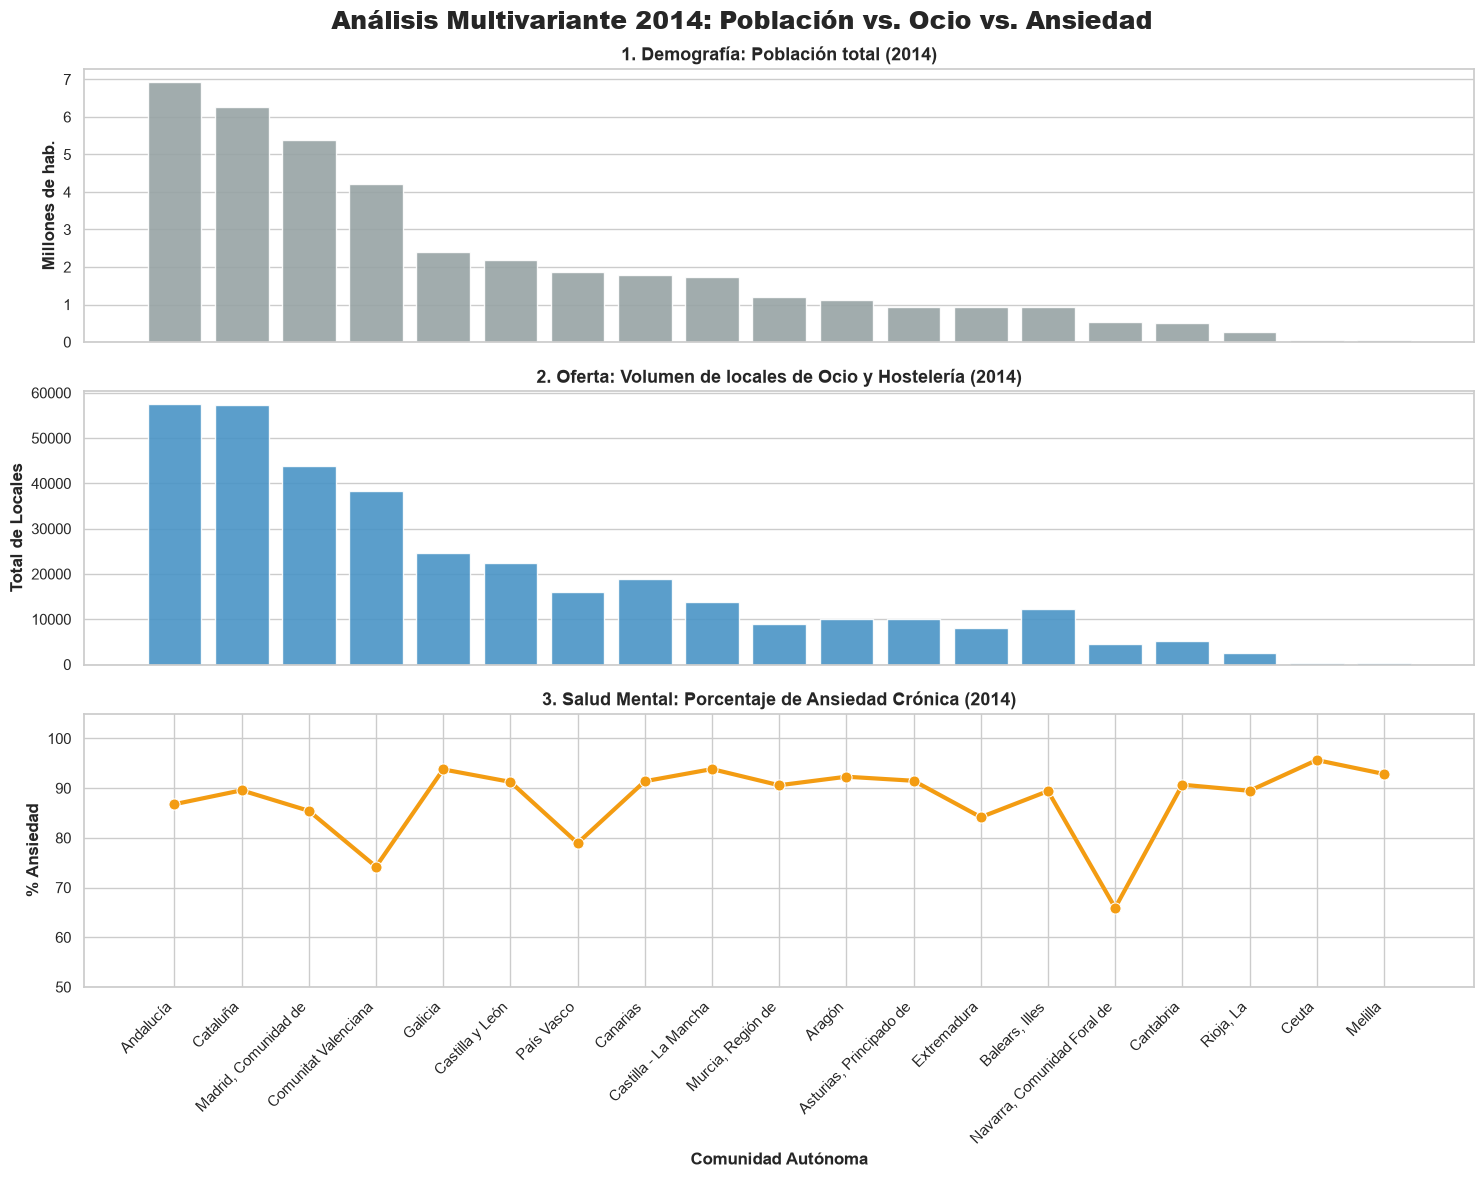

In [11]:
def limpiar_numero(x):
    if isinstance(x, str):
        texto_limpio = x.replace('.', '').replace('%', '').replace(',', '.').strip()
        return float(texto_limpio)
    return float(x)

df_comparativo['Pob_2014_num'] = df_comparativo['Poblacion_2014'].apply(limpiar_numero) / 1000000 # En millones
df_comparativo['Locales_2014_num'] = df_comparativo['Total_Locales_2014'].apply(limpiar_numero)
df_comparativo['Ansiedad_2014_num'] = df_comparativo['Pct_Ansiedad_2014'].apply(limpiar_numero)

#Ordenamos por población de 2014 de mayor a menor
df_triple_2014 = df_comparativo.sort_values('Pob_2014_num', ascending=False)

#CONFIGURACIÓN DEL GRÁFICO TRIPLE (2014)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

#PANEL 1: POBLACIÓN 2014
sns.barplot(ax=axes[0], x=df_triple_2014.index, y=df_triple_2014['Pob_2014_num'], color='#95a5a6', alpha=0.9)
axes[0].set_title('1. Demografía: Población total (2014)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Millones de hab.', fontweight='bold')
axes[0].set_xlabel('') 

#PANEL 2: LOCALES DE OCIO 2014
sns.barplot(ax=axes[1], x=df_triple_2014.index, y=df_triple_2014['Locales_2014_num'], color='#3498db', alpha=0.9)
axes[1].set_title('2. Oferta: Volumen de locales de Ocio y Hostelería (2014)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Total de Locales', fontweight='bold')
axes[1].set_xlabel('')

# PANEL 3: ANSIEDAD 2014
sns.lineplot(ax=axes[2], x=df_triple_2014.index, y=df_triple_2014['Ansiedad_2014_num'], 
             color='#f39c12', marker='o', linewidth=3, markersize=8)
axes[2].set_title('3. Salud Mental: Porcentaje de Ansiedad Crónica (2014)', fontsize=13, fontweight='bold')
axes[2].set_ylabel('% Ansiedad', fontweight='bold')
axes[2].set_ylim(bottom=50, top=105) # Mantenemos la misma escala que en 2025 para que sea comparable
axes[2].set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')

# Ajustar las etiquetas
plt.xticks(rotation=45, ha='right', fontsize=11)

# Título general
fig.suptitle('Análisis Multivariante 2014: Población vs. Ocio vs. Ansiedad', fontsize=18, fontweight='heavy', y=0.98)

plt.tight_layout()
plt.show()

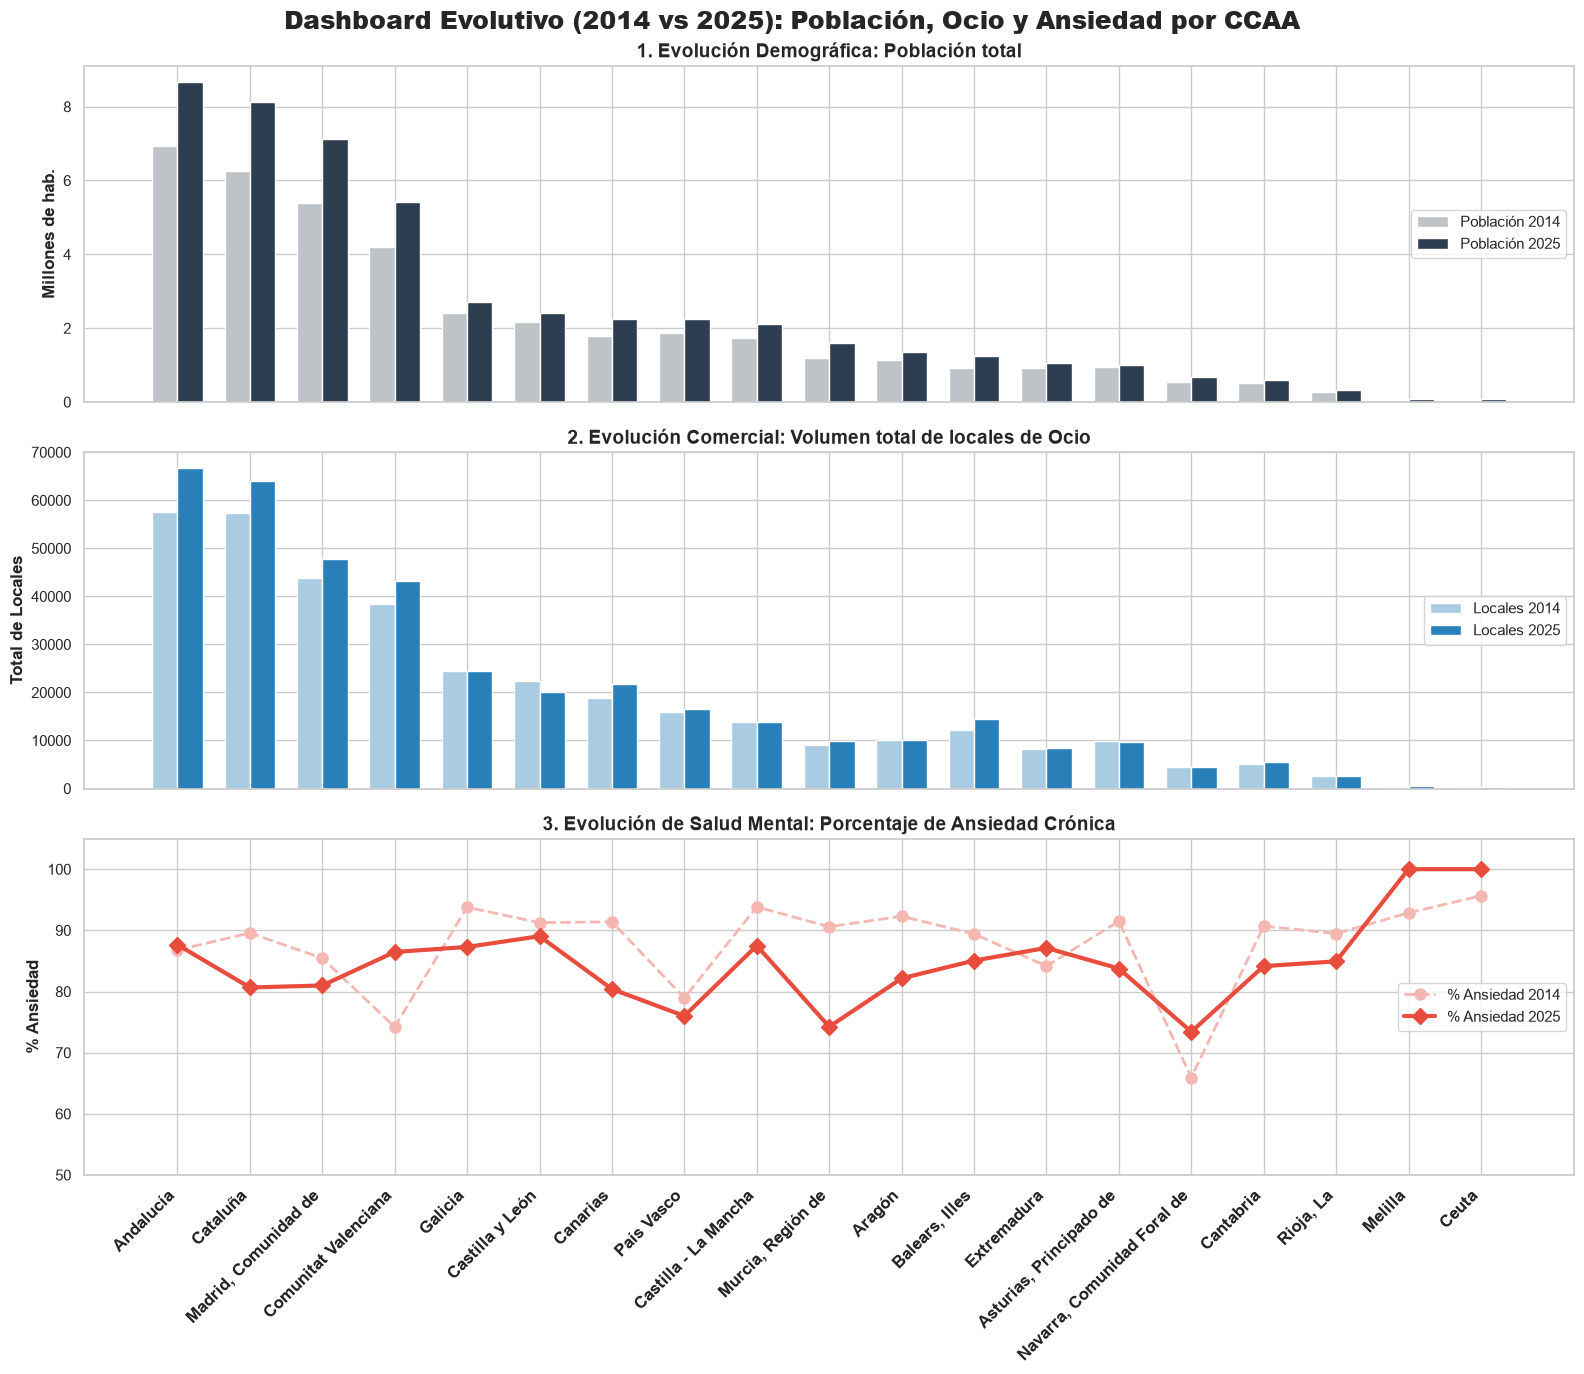

In [12]:
#Aseguramos que tenemos las columnas numéricas limpias del paso anterior
df_triple = df_comparativo.sort_values('Pob_2025_num', ascending=False)

#CONFIGURACIÓN DEL GRÁFICO TRIPLE COMPARATIVO
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)

#Eje X e índice para las barras agrupadas
x = np.arange(len(df_triple.index))
ancho = 0.35

#PANEL 1: EVOLUCIÓN DE LA POBLACIÓN (2014 vs 2025)
axes[0].bar(x - ancho/2, df_triple['Pob_2014_num'], width=ancho, label='Población 2014', color='#bdc3c7')
axes[0].bar(x + ancho/2, df_triple['Pob_2025_num'], width=ancho, label='Población 2025', color='#2c3e50')
axes[0].set_title('1. Evolución Demográfica: Población total', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Millones de hab.', fontweight='bold')
axes[0].legend(loc='center right')

#PANEL 2: EVOLUCIÓN DE LOS LOCALES DE OCIO (2014 vs 2025)
axes[1].bar(x - ancho/2, df_triple['Locales_2014_num'], width=ancho, label='Locales 2014', color='#a9cce3')
axes[1].bar(x + ancho/2, df_triple['Locales_2025_num'], width=ancho, label='Locales 2025', color='#2980b9')
axes[1].set_title('2. Evolución Comercial: Volumen total de locales de Ocio', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total de Locales', fontweight='bold')
axes[1].legend(loc='center right')

#PANEL 3: EVOLUCIÓN DE LA ANSIEDAD (2014 vs 2025)
axes[2].plot(x, df_triple['Ansiedad_2014_num'], label='% Ansiedad 2014', 
             color='#f5b7b1', marker='o', linestyle='--', linewidth=2, markersize=8)
axes[2].plot(x, df_triple['Ansiedad_2025_num'], label='% Ansiedad 2025', 
             color='#e74c3c', marker='D', linestyle='-', linewidth=3, markersize=8)
axes[2].set_title('3. Evolución de Salud Mental: Porcentaje de Ansiedad Crónica', fontsize=14, fontweight='bold')
axes[2].set_ylabel('% Ansiedad', fontweight='bold')
axes[2].set_ylim(bottom=50, top=105)
axes[2].legend(loc='center right')

#Configuración del Eje X (Comunidades Autónomas)
axes[2].set_xticks(x)
axes[2].set_xticklabels(df_triple.index, rotation=45, ha='right', fontsize=12, fontweight='bold')

#Título Principal del Dashboard
fig.suptitle('Dashboard Evolutivo (2014 vs 2025): Población, Ocio y Ansiedad por CCAA', 
             fontsize=18, fontweight='heavy', y=0.98)

plt.tight_layout()
plt.show()

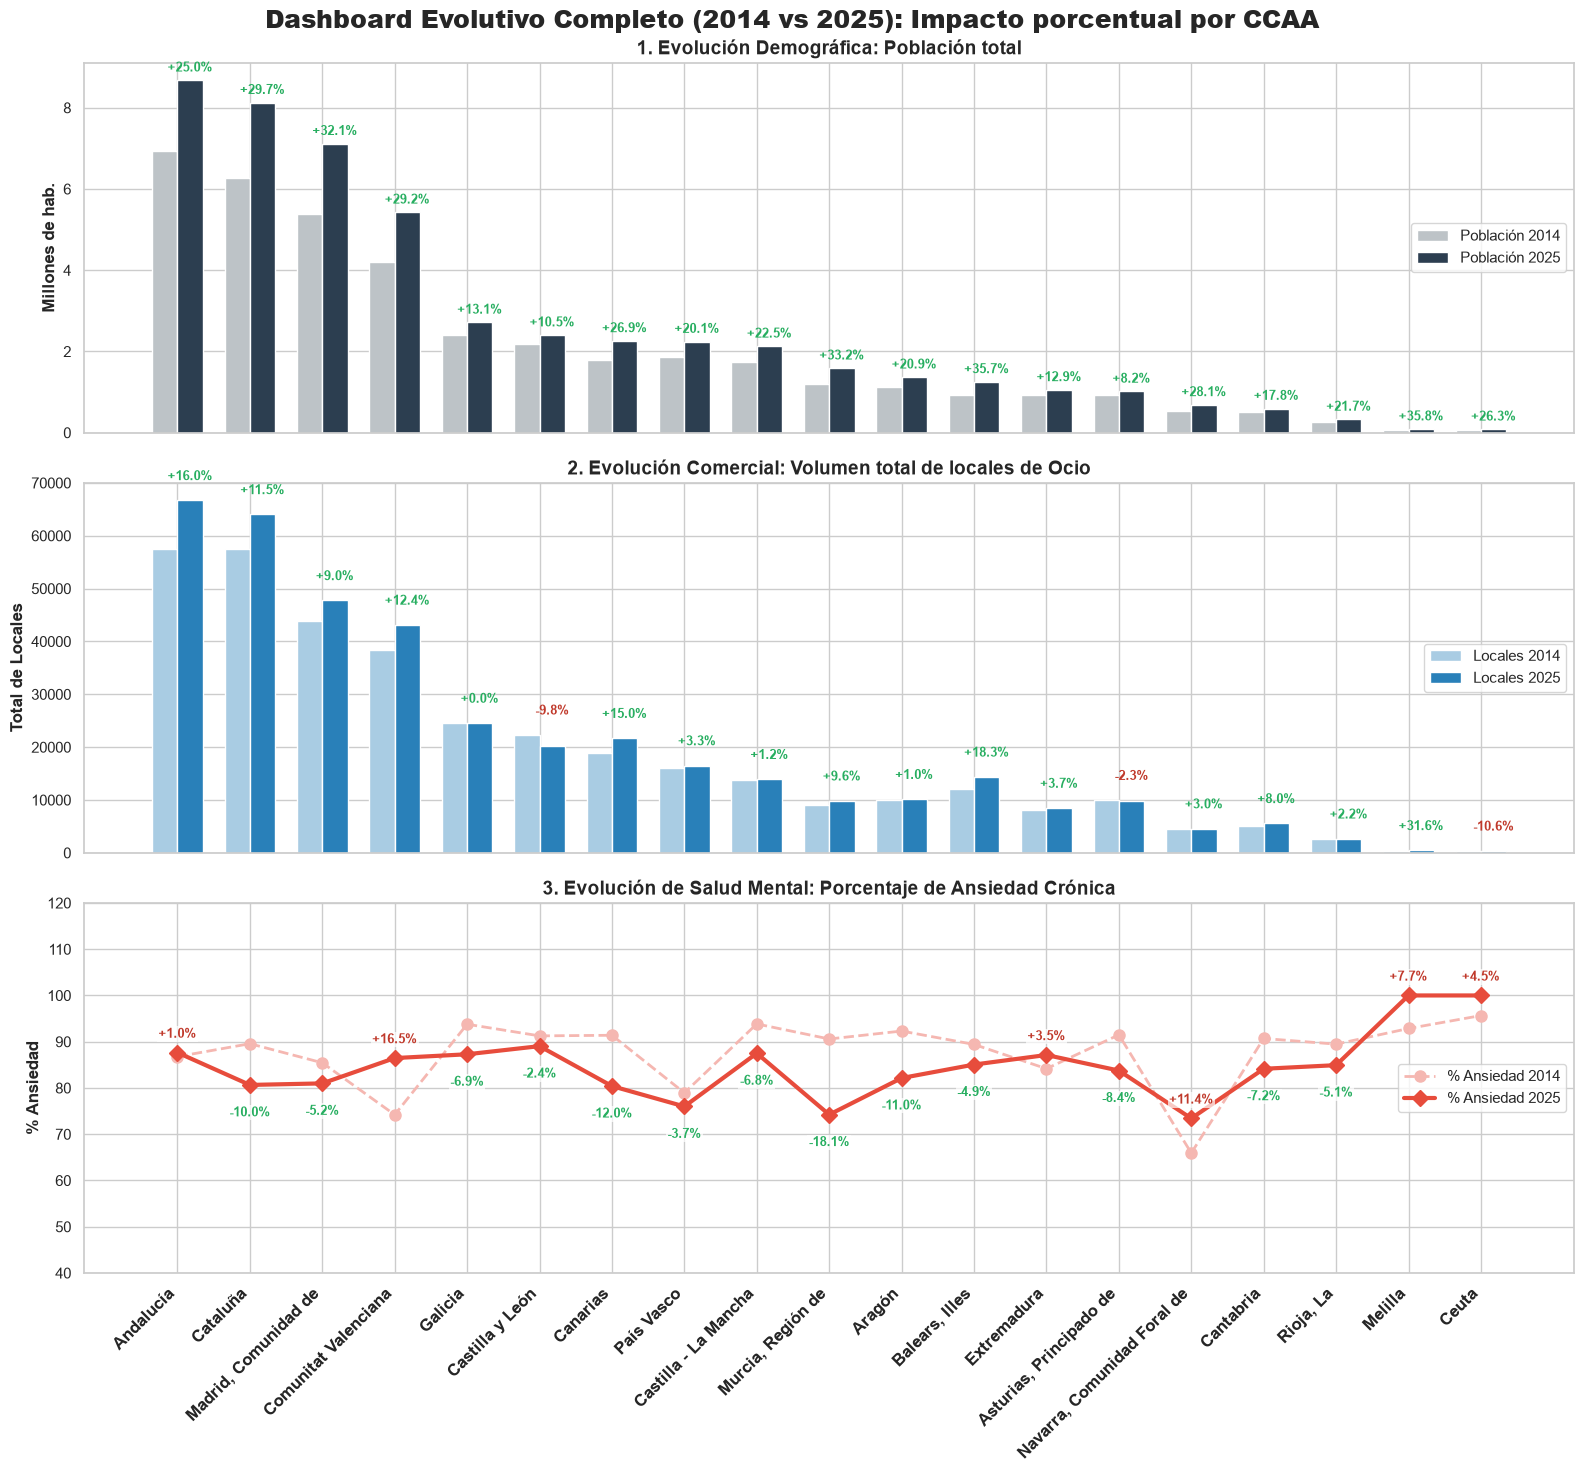

In [13]:
df_triple = df_comparativo.sort_values('Pob_2025_num', ascending=False)

#CONFIGURACIÓN DEL GRÁFICO TRIPLE CON PORCENTAJES
sns.set_theme(style="whitegrid")
#Hacemos la figura un poco más alta (15) para que quepan los textos holgadamente
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)

x = np.arange(len(df_triple.index))
ancho = 0.35

#PANEL 1: POBLACIÓN
axes[0].bar(x - ancho/2, df_triple['Pob_2014_num'], width=ancho, label='Población 2014', color='#bdc3c7')
axes[0].bar(x + ancho/2, df_triple['Pob_2025_num'], width=ancho, label='Población 2025', color='#2c3e50')
axes[0].set_title('1. Evolución Demográfica: Población total', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Millones de hab.', fontweight='bold')
axes[0].legend(loc='center right')

#Bucle para porcentajes de Población
for i in range(len(x)):
    v14 = df_triple['Pob_2014_num'].iloc[i]
    v25 = df_triple['Pob_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    color = '#27ae60' if var_pct > 0 else '#c0392b'
    signo = '+' if var_pct > 0 else ''
    # Colocamos el texto un poco por encima de la barra más alta para que no se superponga
    altura_texto = max(v14, v25) + 0.15
    axes[0].text(x[i] + ancho/2, altura_texto, f'{signo}{var_pct:.1f}%', 
                 ha='center', va='bottom', color=color, fontweight='bold', fontsize=9)

#PANEL 2: LOCALES DE OCIO
axes[1].bar(x - ancho/2, df_triple['Locales_2014_num'], width=ancho, label='Locales 2014', color='#a9cce3')
axes[1].bar(x + ancho/2, df_triple['Locales_2025_num'], width=ancho, label='Locales 2025', color='#2980b9')
axes[1].set_title('2. Evolución Comercial: Volumen total de locales de Ocio', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total de Locales', fontweight='bold')
axes[1].legend(loc='center right')

#Bucle para porcentajes de Locales
margen_locales = df_triple[['Locales_2014_num', 'Locales_2025_num']].max().max() * 0.05
for i in range(len(x)):
    v14 = df_triple['Locales_2014_num'].iloc[i]
    v25 = df_triple['Locales_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    color = '#27ae60' if var_pct > 0 else '#c0392b'
    signo = '+' if var_pct > 0 else ''
    altura_texto = max(v14, v25) + margen_locales
    axes[1].text(x[i] + ancho/2, altura_texto, f'{signo}{var_pct:.1f}%', 
                 ha='center', va='bottom', color=color, fontweight='bold', fontsize=9)

#PANEL 3: ANSIEDAD CRÓNICA
axes[2].plot(x, df_triple['Ansiedad_2014_num'], label='% Ansiedad 2014', 
             color='#f5b7b1', marker='o', linestyle='--', linewidth=2, markersize=8)
axes[2].plot(x, df_triple['Ansiedad_2025_num'], label='% Ansiedad 2025', 
             color='#e74c3c', marker='D', linestyle='-', linewidth=3, markersize=8)
axes[2].set_title('3. Evolución de Salud Mental: Porcentaje de Ansiedad Crónica', fontsize=14, fontweight='bold')
axes[2].set_ylabel('% Ansiedad', fontweight='bold')
axes[2].set_ylim(bottom=40, top=120) # Margen ampliado para que quepan las etiquetas
axes[2].legend(loc='center right')

#Bucle para porcentajes de Ansiedad
for i in range(len(x)):
    v14 = df_triple['Ansiedad_2014_num'].iloc[i]
    v25 = df_triple['Ansiedad_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    
    #Si la ansiedad sube es malo (Rojo), si baja es bueno (Verde)
    color = '#c0392b' if var_pct > 0 else '#27ae60' 
    signo = '+' if var_pct > 0 else ''
    
    #Para que el texto no pise las líneas, lo ponemos arriba o abajo dependiendo de la tendencia
    offset_y = 4 if v25 >= v14 else -6
    axes[2].text(x[i], v25 + offset_y, f'{signo}{var_pct:.1f}%', 
                 ha='center', va='center', color=color, fontweight='bold', fontsize=9,
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)) # Fondo blanco translúcido para leerlo mejor

#Configuración del Eje X
axes[2].set_xticks(x)
axes[2].set_xticklabels(df_triple.index, rotation=45, ha='right', fontsize=12, fontweight='bold')

# Título Principal del Dashboard
fig.suptitle('Dashboard Evolutivo Completo (2014 vs 2025): Impacto porcentual por CCAA', 
             fontsize=18, fontweight='heavy', y=0.98)

plt.tight_layout()
plt.show()